# 08 - Build Final Artifacts (Regenerasi `_fix_final/`)

## Tujuan
Menghitung artefak final yang dipakai dashboard dan skripsi, dengan
**inferensi penuh terhadap seluruh 285 dokumen** sehingga hasilnya
dapat direproduksi ulang setiap kali notebook ini dijalankan.

## Asal (Input)
- `model/lda_model.gensim` (dari Notebook 04)
- `data/intermediate/` (dari Notebook 03)

## Keluaran (Output)
- `topic_distribution_final.csv` - 285 dokumen + matriks theta lengkap
- `topic_counts_final.csv` - jumlah & persentase per topik
- `topic_by_year_final.csv` - matriks tahun x topik + proporsi
- `top_words_final.csv` - kata kunci per topik
- `evaluation_summary.csv` - rekap metrik model

## Mengapa Inferensi Penuh?
Notebook 04 melatih model pada 228 dokumen (80%) lalu memprediksi 285.
Dokumen di hold-out (20%) belum pernah dilihat model, sehingga theta-nya
diffuse dan beberapa dokumen "lompat" ke topik berbeda.

Notebook ini menghilangkan bias itu: seluruh 285 dokumen dinilai oleh model
sehingga setiap dokumen mendapat penugasan topik yang konsisten. Ini juga
menjadikan angka di Tabel 5 dan 13 skripsi dapat direproduksi ulang.

In [1]:
import sys, io as _io
from pathlib import Path
_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(_ROOT))
try:
    sys.stdout.reconfigure(encoding='utf-8', errors='replace')
except Exception:
    pass

import pandas as pd, numpy as np
from src import config as C
C.ensure_dirs()
print(C.describe())

KONFIGURASI PROYEK
  Repo          : C:\Users\HAJIWAHYU\Downloads\lda-topik-skripsi-si-uinrf-main
  Dokumen akhir : 285 (2021, 2022, 2023, 2024, 2025)
  Vocabulary    : 1849
  Model LDA     : K=8, alpha=asymmetric, eta=auto, passes=30, iterations=500, seed=42
  Inferensi     : Online Variational Bayes (bukan Gibbs Sampling)
  C_V resmi     : 0.4256
  Cutoff data   : 19 September 2026

## Langkah 1 - Bangun Artefak Final

In [2]:
from src import build_final as bf

result = bf.run(write=True, verbose=True)

BUILD FINAL ARTIFACTS — inferensi penuh 285 dokumen
  Model  : K=8 | vocabulary=1849
  Dokumen: 285
  Metode : inferensi penuh (tanpa hold-out)

  Distribusi topik:
    Topik 1:  32 dokumen (11.23%)
    Topik 2:  29 dokumen (10.18%)
    Topik 3:  46 dokumen (16.14%)
    Topik 4:  34 dokumen (11.93%)
    Topik 5:  41 dokumen (14.39%)
    Topik 6:  49 dokumen (17.19%)
    Topik 7:  33 dokumen (11.58%)
    Topik 8:  21 dokumen ( 7.37%)
    TOTAL: 285 dokumen

  [OK] 5 artefak ditulis ke _fix_final

## Langkah 2 - Verifikasi Konsistensi

In [3]:
counts = result['counts']
by_year = result['by_year']

print(f'Total dokumen      : {int(counts["jumlah_dokumen"].sum())}')
print(f'Total persentase    : {counts["persentase"].sum():.2f}%')
print()
print('Proporsi per tahun (harus ~100%):')
for _, r in by_year.iterrows():
    s = sum(r[f'proporsi_topik_{t}'] for t in range(1, 9))
    print(f'  {int(r["Tahun"])}: {int(r["total_dokumen"]):3d} dokumen  sum={s:.2f}%')

Total dokumen      : 285
Total persentase    : 100.01%

Proporsi per tahun (harus ~100%):
  2021:  29 dokumen  sum=99.98%
  2022:  78 dokumen  sum=100.01%
  2023:  46 dokumen  sum=100.02%
  2024:  47 dokumen  sum=99.99%
  2025:  85 dokumen  sum=100.01%

## Langkah 3 - Metrik Model (dapat direproduksi)

In [4]:
ev = result['evaluation']
print(ev.to_string(index=False, max_colwidth=70))

                  Metrik                                                               Nilai                                                    Protokol_Keterangan
      Coherence_Score_CV                                                              0.4256 texts=data/intermediate/ (1.849 vocab), topn=20, processes=1, gensi...
   Coherence_Score_UMass                                                            -10.7533                                    corpus BoW 285 dokumen, processes=1
    Train_Log_Perplexity                                                             -7.4518                                          seluruh 285 dokumen korpus v1
   Topic_Diversity_Top10                                                              0.7125                                              proporsi kata unik top-10
   Topic_Diversity_Top15                                                              0.6917                                              proporsi kata unik top-15
Pct_Max_Theta_Un

## Langkah 4 - Visualisasi Distribusi Topik

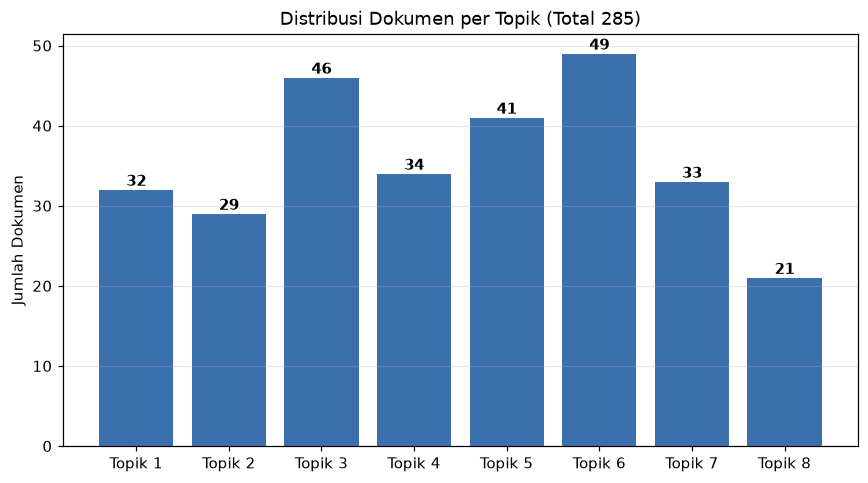

In [5]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

c = result['counts']
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar([f'Topik {int(t)}' for t in c['topik_dominan']],
              c['jumlah_dokumen'], color='#1A56A0', alpha=0.85)
for bar, val in zip(bars, c['jumlah_dokumen']):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            str(int(val)), ha='center', fontweight='bold')
ax.set_ylabel('Jumlah Dokumen')
ax.set_title(f'Distribusi Dokumen per Topik (Total {int(c["jumlah_dokumen"].sum())})')
ax.grid(axis='y', alpha=0.3); plt.tight_layout(); plt.show()

## Ringkasan Fase 08 - Build Final Artifacts

Seluruh artefak di `_fix_final/` kini **dapat direproduksi ulang** dengan
menjalankan notebook ini. Tidak ada lagi angka yang muncul "dari mana-mana".

| File | Jumlah Baris | Status |
|:---|---:|:---|
| `topic_distribution_final.csv` | 285 | dapat direproduksi |
| `topic_counts_final.csv` | 8 | dapat direproduksi |
| `topic_by_year_final.csv` | 5 | dapat direproduksi |
| `top_words_final.csv` | 120 | dapat direproduksi |
| `evaluation_summary.csv` | 9 metrik | dapat direproduksi |

**Catatan metodologis untuk Bab III:** distribusi final dihitung dengan
inferensi penuh terhadap seluruh 285 dokumen (bukan model yang di-split
80/20), sehingga setiap dokumen dinilai secara optimal.

## Peta Artefak

| Artefak | Dibuat oleh | Consumed by |
|:---|:---|:---|
| `_fix_final/topic_distribution_final.csv` | Notebook 08 | app, tests |
| `_fix_final/topic_counts_final.csv` | Notebook 08 | app (Beranda, Distribusi) |
| `_fix_final/topic_by_year_final.csv` | Notebook 08 | Notebook 06, app (Tren) |
| `_fix_final/top_words_final.csv` | Notebook 08 | Notebook 07 (labeling) |